# Ein Roboter sucht den Ball – Referenzlösung

Willkommen im Schnupperstudium! Ein Fußballroboter bekommt Kamerabilder,
aber keine fertige Antwort auf die Frage: **Wo ist der Ball?** Wir entwickeln
eine klassische Bildverarbeitung, zeichnen ihre Entscheidungen ein und prüfen sie fair.
Hier wird kein neuronales Netz trainiert: Wir legen Regeln für Farbe und Form fest.

**Lernziele:** Bildkanäle verstehen, Farbbereiche auswählen, Masken bereinigen,
Objekte als Boxen zurückgeben und Fehler auf echten sowie simulierten Bildern untersuchen.

**Benutzung:** Mit einem Python-Kernel aus der Pixi-Umgebung alle Zellen von oben nach unten
ausführen. Alternativ lassen sich die Code-Zellen mit Python ausführen.
Benötigt werden die vorhandenen Pakete OpenCV, NumPy und Matplotlib sowie
`vision_workshop.py` neben dem Notebook. Das Arbeitsverzeichnis darf der
Repository-Root oder dieser Notebook-Ordner sein. Jupyter selbst ist eine
zusätzliche Oberfläche und wird durch dieses Notebook nicht installiert.
Fehlende Datensätze werden verständlich gemeldet; die übrigen Zellen laufen trotzdem.

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

for candidate in (Path.cwd(), *Path.cwd().parents):
    for helper_dir in (candidate, candidate / "tutorials" / "schnupperstudium"):
        if (helper_dir / "vision_workshop.py").is_file():
            sys.path.insert(0, str(helper_dir))
            break
    else:
        continue
    break
else:
    raise FileNotFoundError("vision_workshop.py fehlt. Bitte vom Repository oder Notebook-Ordner aus starten.")

## Wie sind die Labels aufgebaut?

Jeder Datensatz enthält `images/` und eine `manifest.json`: eine Liste, in der
jeder Eintrag ein Bild beschreibt. Es gibt nur folgende Angaben:

- `image`: relativer Pfad zum Bild.
- `boxes`: Ballrechtecke als `[links, oben, rechts, unten]` in Bildpixeln.
  Eine leere Liste bedeutet: kein Ball. Rechts und unten liegt die Grenze
  direkt hinter dem letzten zugehörigen Pixel.
- `source`: `real` für Kameraaufnahmen oder `simulation` für simulierte Bilder.
- `split`: `train` zum Entwickeln oder `test` für den Abschlusstest.

Die Notebooks benötigen keine gespeicherten Segmentierungsmasken.



In [2]:
from vision_workshop import (
    box_iou,
    dataset_summary,
    evaluate,
    load_dataset,
    plot_debug,
    plot_metrics,
    plot_overview,
    print_evaluation,
)

plt.rcParams["figure.dpi"] = 100
print("Bereit: OpenCV-Bilder sind BGR; Matplotlib bekommt RGB.")

Bereit: OpenCV-Bilder sind BGR; Matplotlib bekommt RGB.


## Datensätze herunterladen oder offline verwenden

Die Download-URLs sind in der folgenden Zelle bereits eingetragen.
Vollständige lokale Datensätze brauchen kein Internet.
Die Downloadzelle prüft und entpackt fehlende Datensätze mit `wget`.


In [3]:
DATASET_URLS = {
    "orange": "https://data.bit-bots.de/Schnupperstudium2026/orange.tar.gz",
    "realistic": "https://data.bit-bots.de/Schnupperstudium2026/realistic.tar.gz",
}

In [4]:
from download_datasets import DatasetDownloadError, ensure_datasets

try:
    ensure_datasets(DATASET_URLS)
except DatasetDownloadError as error:
    print(f"Datensätze noch nicht bereit: {error}")
    print("Bitte die Meldung prüfen und diese Zelle danach erneut ausführen.")

orange: lokale Daten geprüft, kein Download nötig.
realistic: lokale Daten geprüft, kein Download nötig.


## Daten ansehen, bevor wir Regeln erfinden

Zu jedem Bild gehören Referenzboxen und Angaben zur Herkunft und Verwendung.
`source` unterscheidet echte Bilder (`real`) und Simulation (`simulation`);
`split` trennt Trainingsbilder (`train`) von Testbildern (`test`).

`boxes` enthält die vorgegebenen und geprüften **Referenzboxen (Ground Truth)**.
Bilder ohne Ball haben eine leere Liste – wir erfinden
dafür keine Ballbox! Die Koordinaten sind Pixel im Format
`[xmin, ymin, xmax, ymax]`; rechte und untere Grenze gehören nicht mehr zur Box.
Es können mehrere Bälle in einem Bild vorkommen.

Der Loader lädt bewusst eine kleine, nach Quelle und Ballpräsenz gemischte
Trainingsauswahl. Die Übersicht beschreibt nur diese Auswahl. Vergrößere sie
bei Bedarf im Code; die vollständige Auswertung erfolgt später ohne Limit.
Die Simulationsbilder wurden mit MuJoCo gerendert; die realistischen Bilder
stammen aus dem annotierten TORSO-Datensatz. Es sind keine KI-generierten Bilder.

Die folgende Übersicht zeigt den aktuellen Datenumfang nach Quelle und Ballpräsenz.
Kennzahlen gelten für die tatsächlich geladenen Bilder.


Vorhandene Gruppen: {'real': {'positive': 100, 'negative': 100}, 'simulation': {'positive': 100, 'negative': 100}}
Trainingsbilder geladen: 32
Bildformat: (376, 672, 3)
Erste Annotation: [[437. 120. 479. 160.]]


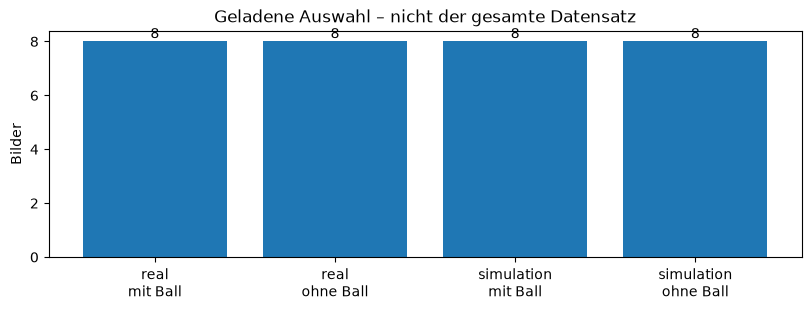

In [5]:
DATASET = "orange"
TRAIN_LIMIT = 32

try:
    summary = dataset_summary(DATASET)
    print("Vorhandene Gruppen:", summary["counts"])
    for warning in summary["warnings"]:
        print(warning)
    train_records = load_dataset(DATASET, split="train", limit=TRAIN_LIMIT)
except FileNotFoundError as error:
    print(f"Noch keine verwendbaren Workshop-Daten: {error}")
    print("Nach Bereitstellung der Daten diese und die folgenden Zellen erneut ausführen.")
    train_records = []

print(f"Trainingsbilder geladen: {len(train_records)}")
if train_records:
    print("Bildformat:", train_records[0]["image_bgr"].shape)
    print("Erste Annotation:", train_records[0]["boxes"])
    plot_overview(train_records)
    plt.show()

## RGB und BGR: Gleiche Zahlen, andere Reihenfolge

Matplotlib erwartet normalerweise **Rot, Grün, Blau (RGB)**. OpenCV liest
**Blau, Grün, Rot (BGR)**. Gibst du ein OpenCV-Bild unverändert an Matplotlib,
werden Rot und Blau vertauscht. Das ist ein Darstellungsfehler, kein neuer Ball!

**Aufgabe:** Vergleiche die folgenden Ansichten. Welcher Kanal steckt jeweils
am Anfang? Warum sollte der Detektor weiterhin das ursprüngliche BGR-Bild erhalten?

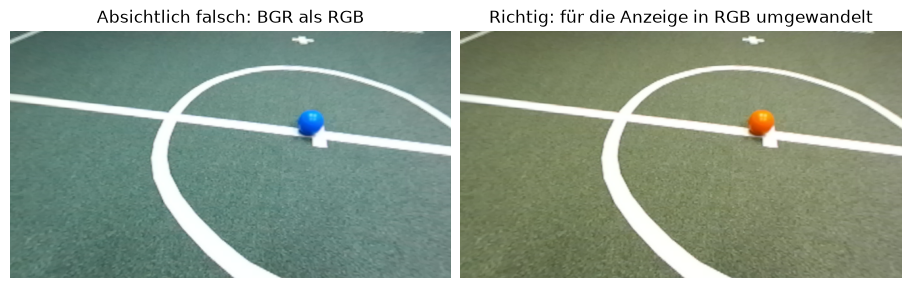

In [6]:
if train_records:
    image_bgr = train_records[0]["image_bgr"]
    figure, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
    axes[0].imshow(image_bgr)
    axes[0].set_title("Absichtlich falsch: BGR als RGB")
    axes[1].imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
    axes[1].set_title("Richtig: für die Anzeige in RGB umgewandelt")
    for axis in axes:
        axis.axis("off")
    plt.show()
else:
    print("Für den Farbvergleich werden Datensatzbilder benötigt.")

## Von der Farbe zur Ballbox

**HSV** beschreibt Farbton (Hue), Sättigung (Saturation) und Helligkeit (Value).
Damit lässt sich Orange leichter von Schatten und weißen Flächen unterscheiden
als durch unabhängige RGB-Grenzen. OpenCV kodiert HSV in seinem eigenen
Ganzzahlbereich; die Grenzen im Code beziehen sich auf diese Darstellung,
nicht direkt auf Winkelangaben. Bei roten Farbtönen muss man den Übergang am
Ende des Farbtonbereichs beachten. HSV macht das Verfahren nicht automatisch
unabhängig von Beleuchtung, Weißabgleich oder einer anderen Kamera.

Eine **Maske** markiert passende Pixel hell, alle anderen dunkel.
**Öffnen** entfernt kleine Flecken; **Schließen** füllt kleine Lücken.
Zu starke Morphologie kann kleine oder benachbarte Bälle zerstören.
**Konturen** umranden zusammenhängende Flächen. Aus ihnen gewinnen wir
Boxen und prüfen Fläche, Rundheit, Seitenverhältnis und Flächenfüllung.
Orange Gegenstände können trotzdem fälschlich wie Bälle aussehen.

**Arbeitsauftrag:**
- Wandle BGR mit `cv2.cvtColor` in HSV um.
- Wähle mit `cv2.inRange` den orangefarbenen Bereich.
- Bereinige die Maske mit `cv2.morphologyEx`.
- Suche Konturen mit `cv2.findContours` und prüfe ihre Form.
- Nutze `cv2.boundingRect`; rechne Breite und Höhe in die Endkoordinaten um.
- Gib immer ein NumPy-Array der Form `(N, 4)` zurück, auch wenn kein Ball gefunden wird.

Die folgende Referenzlösung setzt diese Schritte in `detect_balls` um.
Sie sucht orangefarbene, ballähnliche Flächen und gibt deren Boxen zurück.
Ohne passende Kontur liefert sie ein leeres Array im vereinbarten Format.
Annotationen und Auswertung bleiben unverändert; Debugbilder machen die Entscheidungen nachvollziehbar.

In [7]:
def detect_balls(image_bgr: np.ndarray) -> np.ndarray:
    """Erkenne orange Bälle und liefere xyxy-Pixelboxen, ohne das Bild zu ändern."""
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, np.array([5, 100, 80]), np.array([30, 255, 255]))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), dtype=np.uint8))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for contour in contours:
        area = cv2.contourArea(contour)
        perimeter = cv2.arcLength(contour, True)
        if area < 30 or perimeter == 0:
            continue
        if 4 * np.pi * area / perimeter**2 < 0.75:
            continue
        left, top, width, height = cv2.boundingRect(contour)
        if not 0.75 <= width / height <= 1.33:
            continue
        boxes.append([left, top, left + width, top + height])
    return np.asarray(boxes, dtype=np.float64).reshape(-1, 4)

### Was macht die Referenz – und was nicht?


Die Funktion verwendet nur die bereits importierten Module `cv2` und `np`,
keine weiteren Notebook-Variablen oder Helper. Ihr Funktionskörper lässt sich
in `src/bitbots_vision/schnupper_vision/detector.py` übernehmen,
sofern er ein BGR-Array erhält. Die Rückgabe besteht aus Pixelboxen, nicht
aus Richtungen, Entfernungen oder ROS-Nachrichten. Das Eingabebild wird nicht verändert.
Der Detektor verwendet **keine Ground Truth**. Die Parameter stehen ausschließlich
im Code und sind eine Ausgangshypothese, kein behauptetes Optimum für die Daten.

Rundheit vergleicht Fläche mit Umfang: Eine kompakte, kreisähnliche Fläche
schneidet besser ab als eine lange dünne. Kleine abgeschnittene, verdeckte oder
schlecht beleuchtete Bälle können dadurch verloren gehen. Die Grenzen muss man
an Trainingsbildern untersuchen, nicht mit Blick auf die Testantworten nachregeln.

**Optionale Erweiterung:** `cv2.HoughCircles` sucht Kreisstrukturen und kann
eine andere Formprüfung liefern. Es braucht ein geeignetes Graubild und
sorgfältige Einstellungen; Perspektive, Verdeckung und Kreisstrukturen im
Hintergrund bleiben schwierig. Es ist keine Voraussetzung für diesen Workshop.

## Wie bewerten wir eine Vorhersage fair?

**IoU** ist die Fläche der Überlappung geteilt durch die Fläche der Vereinigung.
Die Schwelle steht in der Auswertungszelle. Sie bleibt während des Vergleichs unverändert.
Boxen werden nur innerhalb desselben Bildes verglichen. Jede Vorhersage und
jede GT-Box darf höchstens einem Treffer zugeordnet werden. Der Helper sucht
ein Matching mit möglichst vielen gültigen Paaren; größere IoU wird bei der
Suche zuerst berücksichtigt. Er optimiert nicht die Summe der IoU-Werte.

- **TP:** einer GT-Box eindeutig zugeordnete Vorhersage.
- **FP:** Vorhersage ohne zugeordnete GT-Box, auch eine doppelte Meldung desselben Balls.
- **FN:** GT-Ball ohne zugeordnete Vorhersage.
- **Precision:** Anteil der richtigen Meldungen an allen Meldungen.
- **Recall:** Anteil der gefundenen Bälle an allen annotierten Bällen.
- **F1:** harmonisches Mittel von Precision und Recall.

Zuerst werden die Treffer und Fehler über die Bilder addiert, danach die Kennzahlen
berechnet (**Mikro-Mittelung**). Wir mitteln nicht einfach Bild-Prozentwerte.
Bei leerem Nenner meldet der Helper null statt eines undefinierten Werts.
Ein leeres negatives Bild erzeugt weder TP noch FN; eine Meldung darauf ist FP.
Gute Ergebnisse auf Negativen sind daher nicht als zusätzliche Balltreffer sichtbar.

In [8]:
example_truth = np.array([[10, 10, 50, 50]])
example_prediction = np.array([[20, 10, 60, 50]])
print("IoU des Rechenbeispiels:", box_iou(example_prediction, example_truth))
empty_result = detect_balls(np.zeros((64, 64, 3), dtype=np.uint8))
assert isinstance(empty_result, np.ndarray) and empty_result.ndim == 2 and empty_result.shape[1] == 4
print("Detektorvertrag auf einem leeren Prüfbild:", empty_result.shape)

IoU des Rechenbeispiels: [[0.6]]
Detektorvertrag auf einem leeren Prüfbild: (0, 4)


Training · overall: {'tp': 13, 'fp': 0, 'fn': 3, 'precision': 1.0, 'recall': 0.8125, 'f1': 0.896551724137931}
  Bilder: 32; positive Bilder: 16
Training · real: {'tp': 5, 'fp': 0, 'fn': 3, 'precision': 1.0, 'recall': 0.625, 'f1': 0.7692307692307693}
  Bilder: 16; positive Bilder: 8
Training · simulation: {'tp': 8, 'fp': 0, 'fn': 0, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0}
  Bilder: 16; positive Bilder: 8


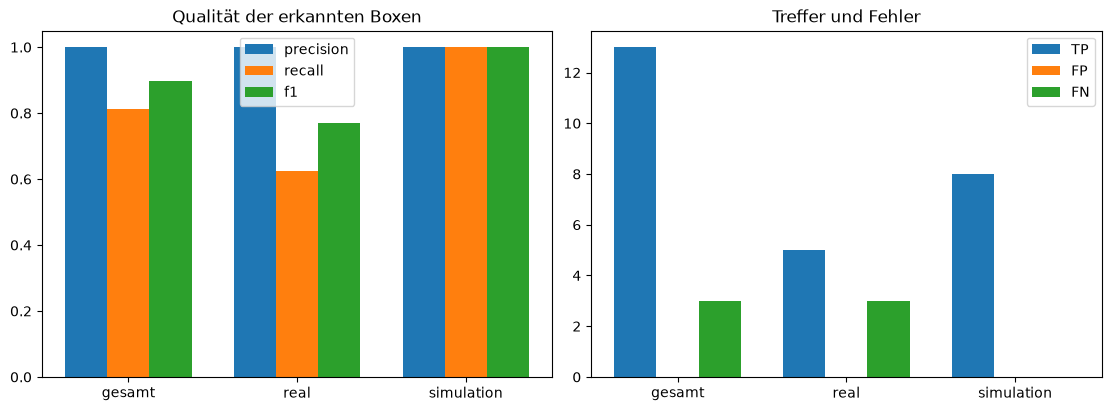

In [9]:
train_result = evaluate(train_records, detect_balls, threshold=0.5)
print_evaluation(train_result, "Training")
if train_records:
    plot_metrics(train_result)
    plt.show()

## Fehler sichtbar machen

Grün markiert die vorgegebenen Boxen, Magenta deine Vorhersagen. Die Bilder
werden nur zur Anzeige nach RGB umgewandelt. Daneben siehst du den Farbton
als Graubild sowie die rohe und bereinigte HSV-Maske der Referenz-Pipeline.
**Wichtig:** Die Diagnosemasken stammen aus `orange_masks` im Helper;
bei eigenen Änderungen am Detektor sind sie nicht automatisch dessen interne Masken.
Halte beide Pipelines für einen direkten Vergleich synchron oder zeige deine eigene Maske.

Wir wählen, soweit verfügbar, positive und negative Beispiele aus jeder Quelle.
**Aufgabe:** Finde einen FP und einen FN. War die Farbe falsch, die Maske
unterbrochen oder die Formprüfung zu streng? Ändere jeweils nur eine Idee,
führe die Detektor- und Trainingsauswertungszellen erneut aus und notiere den Effekt.

images/real_ID_romeo_2026-10-16T18_05_34_00245.png {'tp': 1, 'fp': 0, 'fn': 0}


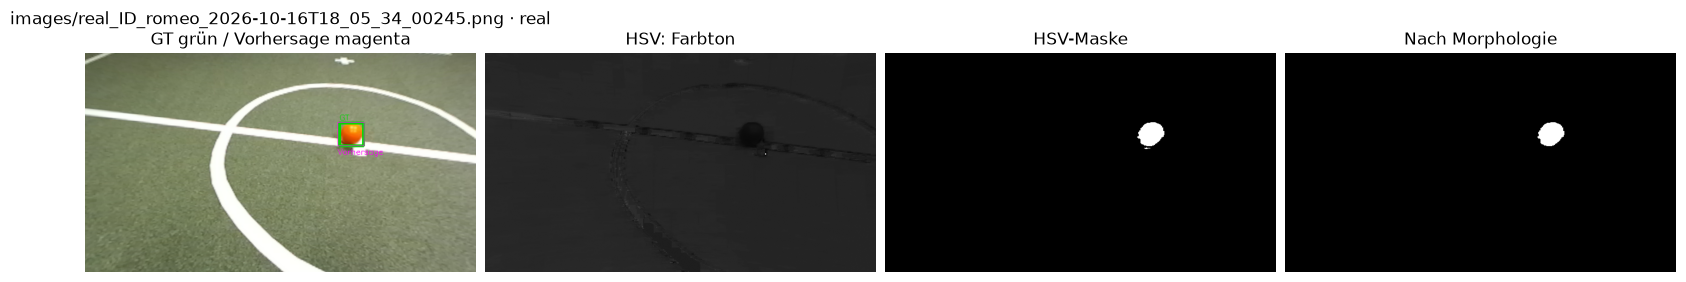

images/real_ID_romeo_2026-10-16T18_05_34_00033.png {'tp': 0, 'fp': 0, 'fn': 0}


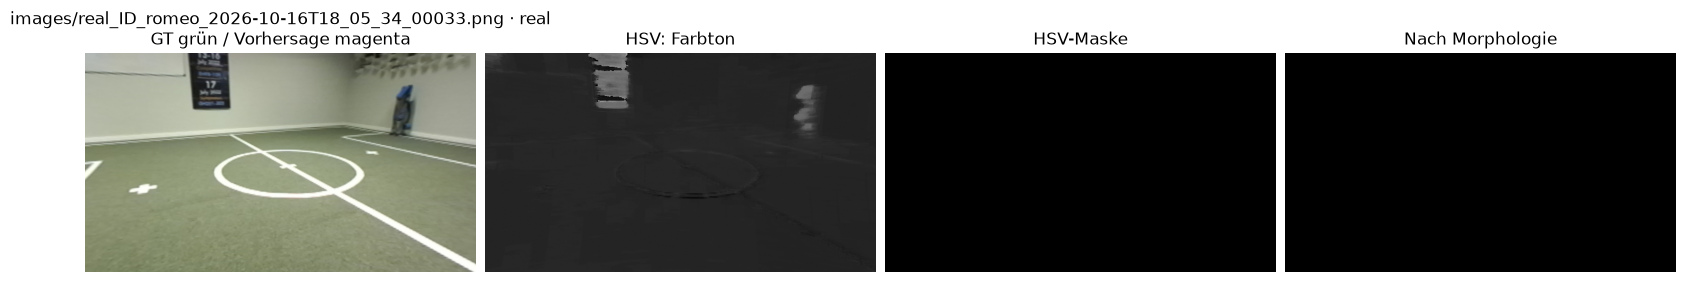

images/sim_orange_train_positive_0000.png {'tp': 1, 'fp': 0, 'fn': 0}


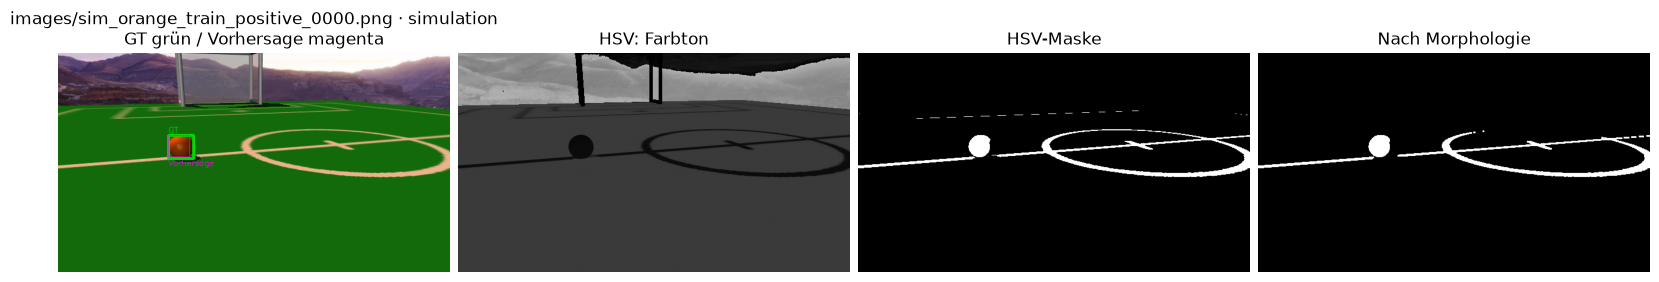

images/sim_orange_train_negative_0000.png {'tp': 0, 'fp': 0, 'fn': 0}


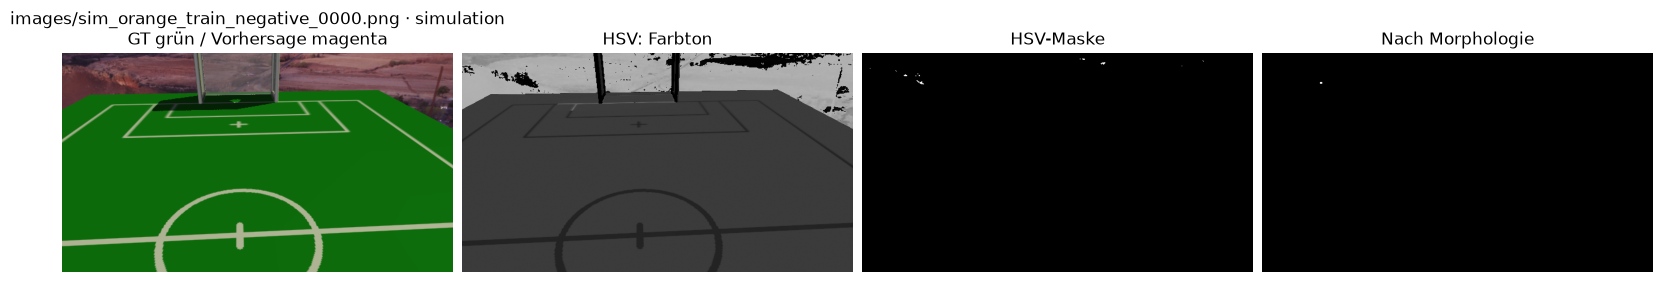

In [10]:
examples = []
for source in ("real", "simulation"):
    for positive in (True, False):
        example = next(
            (
                item
                for item in train_result["items"]
                if item["record"]["source"] == source and bool(len(item["record"]["boxes"])) == positive
            ),
            None,
        )
        if example is not None:
            examples.append(example)

for item in examples:
    print(item["record"]["id"], {key: item[key] for key in ("tp", "fp", "fn")})
    plot_debug(item["record"], item["predicted"])
    plt.show()
if not examples:
    print("Debugbilder erscheinen, sobald die Daten vorhanden sind.")

## Erst üben, dann testen – kein Abschreiben vom Testsatz

Obwohl wir kein lernendes Modell fitten, sind Farbschwellen und Formregeln
Entscheidungen anhand von Daten. Auch das ist eine Art Training!
Nutze dafür ausschließlich `train`. Vergleiche Änderungen auf derselben Auswahl;
prüfe anschließend die ganze Trainingsmenge, bevor du den Testsatz öffnest.

Lege die endgültige Funktion und die IoU-Schwelle fest. Erst dann schalte
`RUN_FINAL_TEST` ein. Es werden alle Bilder des vorgegebenen Test-Splits geladen.
Ändere nach Sichtung der Testergebnisse keine Parameter mehr für denselben
Leistungsvergleich: Sonst wird der Test unbemerkt zum Training (**Leakage**).
Zufälliges Neumischen im Notebook wäre ebenfalls unfair. Ähnliche Aufnahmen
aus derselben Szene sollten bereits bei der Datenaufteilung zusammenbleiben;
die vorhandenen Splits sind keine Garantie gegen jede Szenenähnlichkeit.

In [11]:
RUN_FINAL_TEST = False

if RUN_FINAL_TEST:
    try:
        test_records = load_dataset(DATASET, split="test", limit=None)
    except FileNotFoundError as error:
        print(error)
        test_records = []
    test_result = evaluate(test_records, detect_balls, threshold=0.5)
    print_evaluation(test_result, "Abschlusstest")
    if test_records:
        plot_metrics(test_result)
        plt.show()
else:
    print("Test bleibt geschlossen. Erst nach Abschluss aller Entscheidungen freigeben.")

Test bleibt geschlossen. Erst nach Abschluss aller Entscheidungen freigeben.


## Transfer: Funktioniert dieselbe Idee auf realistic?

Der realistische Datensatz enthält echte und simulierte Szenen mit schwierigerem
Hintergrund und anderen Ballerscheinungen. **Vermutung vor dem Versuch:**
Wo wird die reine Orange-Regel scheitern? Welche Unterschiede erwartest du
zwischen `real` und `simulation`? Eine Referenzlösung ist keine Garantie für hohe Werte.

Schalte `RUN_TRANSFER` erst nach Abschluss des orange-Experiments ein.
Nutze dieselbe Funktion unverändert auf dem Test-Split von `realistic`.
Untersuche Kennzahlen nach Quelle sowie die angezeigten Fehlbeispiele.
Ein weißer oder gemusterter Ball muss nicht in einer Orange-Maske erscheinen!
Ein dunkler Hintergrund oder ein oranges Trikot kann dagegen zu FP führen.

Falls du anschließend bewusst einen besseren realistic-Detektor entwickeln willst,
beginne eine getrennte Versuchsreihe mit dessen Trainings-Split. Der bereits
angesehene Testsatz ist dann kein unangetasteter Schlussvergleich mehr.

In [12]:
RUN_TRANSFER = False

if RUN_TRANSFER:
    try:
        transfer_records = load_dataset("realistic", split="test", limit=None)
    except FileNotFoundError as error:
        print(error)
        transfer_records = []
    transfer_result = evaluate(transfer_records, detect_balls, threshold=0.5)
    print_evaluation(transfer_result, "Transfer")
    if transfer_records:
        plot_metrics(transfer_result)
        plt.show()
        failures = [item for item in transfer_result["items"] if item["fp"] or item["fn"]]
        for item in failures[:3]:
            plot_debug(item["record"], item["predicted"])
            plt.show()
else:
    print("Transfer bleibt geschlossen, bis der orange-Detektor fertig ist.")

Transfer bleibt geschlossen, bis der orange-Detektor fertig ist.


## Dein Forschungsprotokoll

Ergänze hier deine Antworten:

- **Hypothese:** Welche Bildmerkmale sprechen für einen Ball?
- **Training:** Welche Änderung hat geholfen? Welche hat mehr FP oder FN verursacht?
- **Negative Bilder:** Was meldet dein Detektor, obwohl gar kein Ball da ist?
- **Test:** Wie unterscheiden sich Precision, Recall und F1 vom Training?
- **Quelle:** Welche Unterschiede zwischen echten und simulierten Bildern fallen auf?
- **Transfer:** Welche Annahme der Orange-Regel passt nicht mehr zu realistic?
- **Grenzen:** Welche schwierigen Situationen fehlen vielleicht in den Daten?

Für eine Weiterverwendung im Roboter reicht eine gute Notebook-Kennzahl allein
nicht: Laufzeit, Kamerabilder, Beleuchtung, verdeckte Bälle und sichere Integration
müssen ebenfalls geprüft werden. Dieses Notebook startet keine Roboterprozesse.

**Für Betreuende:** Die Offline-Tests in `test_workshop.py` prüfen IoU,
eindeutige Zuordnungen, Fehlerzähler, leere Ergebnisse und die Trennung nach Quelle.
Aus dem Repository lassen sie sich mit
`/home/jan/.pixi/bin/pixi run -e default python -m pytest tutorials/schnupperstudium/test_workshop.py -q`
ausführen. Die Lösung ist eine erklärbare Baseline, kein anhand des Tests optimierter Benchmark.